# [ML 미니과제1] 다이아몬드가격예측

## KANT Jewelry · 다이아몬드 가격 예측

#### 머신러닝 기초 · 미니과제(2일)
- KANT 쇼핑몰이 보석 카테고리를 엽니다. 새로 들어오는 다이아몬드마다 감정사가 가격을 매기기엔 시간이 너무 걸려서, MD 팀이 무게만 넣으면 적정 가격을 추천하는 모델을 요청했습니다. 공개 데이터 53,940개로 이 모델을 만들고, 얼마나 믿을 만한지 보고하세요.

#### 이 과제에서 증명할 것
- 1장 · 2장에서 배운 데이터 점검 · 그래프 · 선형 회귀만으로 하나의 예측 모델을 처음부터 끝까지 만들고, 그 한계를 그림으로 설명할 수 있다. 새로 배워야 하는 것은 없습니다.

### 진행 방법과 규칙

- 노트북 **한 개**(`diamond.ipynb`)로 M1 부터 M5 까지 순서대로 진행합니다. 미션마다 마크다운 셀로 제목을 달고, 그 미션의 **생각해 볼 질문** 답을 같은 마크다운 셀에 적어 주세요.
- 무작위가 들어가는 곳은 모두 `random_state=42` 로 고정합니다. 그래야 아래 **확인용 기준값**과 비교할 수 있습니다.
- 각 미션의 **힌트**는 막혔을 때만, **확인용 기준값**은 다 하고 나서 펼치세요. 정답 코드는 없습니다. 수업 노트북을 다시 찾아보는 것이 가장 좋은 힌트입니다.

### 데이터 소개

- sns.load_dataset("diamonds") · 다이아몬드 53,940개의 무게 · 등급 · 크기 · 판매 가격. 각 행이 다이아몬드 하나입니다. 이번 과제에서 모델에 넣는 것은 숫자 열뿐이며, cut · color · clarity(글자 등급)는 3장에서 숫자로 바꾸는 방법을 배운 뒤 씁니다.

| 열 | 뜻 | 종류 |
| --- | --- | --- |
| `carat` | 무게(캐럿, 1캐럿 = 0.2g) | 숫자 |
| `cut` | 연마 등급 · Ideal > Premium > Very Good > Good > Fair | 등급(category) |
| `color` | 색 등급 · D(무색, 최고) → J(노란빛, 최저) | 등급(category) |
| `clarity` | 투명도 등급 · IF(최고) > VVS1 > VVS2 > VS1 > VS2 > SI1 > SI2 > I1(최저) | 등급(category) |
| `depth` | 깊이 비율(%) = 높이 ÷ 평균 지름 × 100 | 숫자 |
| `table` | 윗면(테이블) 너비 ÷ 전체 너비 (%) | 숫자 |
| `x · y · z` | 가로 · 세로 · 높이 (mm) | 숫자 |
| `price` | **가격(달러) · 예측할 정답** | 숫자 |

### M1 · 데이터 불러오기

#### 생각해 볼 질문
- price의 평균과 중앙값 중 어느 쪽이 더 큰가?
  평균(약 3,933달러)이 중앙값(약 2,401달러)보다 훨씬 큽니다.
- 그 차이는 가격 분포에 대해 무엇을 말해 주는가?
  대부분의 다이아몬드는 비교적 저렴한 가격대에 몰려 있지만, 극도로 비싼 고가 다이아몬드들이 오른쪽으로 길게 늘어서며 평균을 위로 끌어올리고 있다는 뜻입니다(오른쪽으로 꼬리가 긴 분포).

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 한글 폰트 설정 (Windows 기준, Mac 사용 시 "AppleGothic" 등으로 변경 가능)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False  # 마이너스(-) 기호 깨짐 방지

In [12]:
# diamonds 데이터 불러오기
df = sns.load_dataset("diamonds")

print("데이터 크기(행, 열):", df.shape)
display(df.head())

print("\n--- 자료형 및 빈칸(결측치) 확인 ---")
df.info()

print("\n--- 숫자 열 기초 통계 ---")
display(df.describe())

데이터 크기(행, 열): (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75



--- 자료형 및 빈칸(결측치) 확인 ---
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB

--- 숫자 열 기초 통계 ---


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


### M2 · 이상치 정리

#### 생각해 볼 질문
- 어떤 행을 왜 지웠는가?
  1) 가로(`x`), 세로(`y`), 높이(`z`) 중 하나라도 `0`인 행(20개): 실제 다이아몬드 크기가 0mm일 수 없으므로 잘못 기록된 값입니다.
  2) 세로(`y`)나 높이(`z`)가 `20mm`를 넘는 행(3개): 다른 표본과 비교해 비정상적으로 큰 크기 값이라 이상치로 판단해 제거했습니다.
- 비싼 다이아몬드는 왜 지우면 안되는가?
  가격이 높다는 것 자체는 오류나 입력 실수가 아니라 실제로 비싸게 거래되는 진짜 값이기 때문입니다. 진짜 데이터를 지우면 실제 시장 가격 구조를 왜곡하게 됩니다.

In [13]:
# 1) x, y, z 각각 0인 값 개수 세기
print("x == 0 개수:", (df["x"] == 0).sum())
print("y == 0 개수:", (df["y"] == 0).sum())
print("z == 0 개수:", (df["z"] == 0).sum())

# 2) x, y, z 중 하나라도 0인 행 개수 확인 및 조회
zero_rows = df[(df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)]
print("\nx, y, z 중 하나라도 0인 행 수:", len(zero_rows))
zero_rows

x == 0 개수: 8
y == 0 개수: 7
z == 0 개수: 20

x, y, z 중 하나라도 0인 행 수: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [14]:
# 3) y 또는 z가 20mm를 넘는 행 조회
big_rows = df[(df["y"] > 20) | (df["z"] > 20)]
print("y 또는 z가 20mm 초과인 행 수:", len(big_rows))
big_rows

y 또는 z가 20mm 초과인 행 수: 3


,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [15]:
# 4) 두 종류의 이상한 행을 모두 제외한 clean 표 만들기
clean = df[
    ~((df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0) | (df["y"] > 20) | (df["z"] > 20))
].copy()

print("제거 전 행 수:", len(df))
print("제거 후 clean 행 수:", len(clean))
print("제거된 행 수:", len(df) - len(clean))

제거 전 행 수: 53940
제거 후 clean 행 수: 53917
제거된 행 수: 23


### M3 · 그래프와 상관계수

#### 생각해 볼 질문
- 왜 carat을 골랐는가?
  숫자 열 중 `price`와의 상관계수가 약 `0.922`로 가장 높아, 무게(`carat`)가 커질수록 가격이 오르는 경향이 가장 뚜렷하기 때문입니다.
- 산점도에서 직선 하나로 맞추기 어려워 보이는 부분은 어디인가?
  무게가 커질수록 점들이 위아래로 넓게 퍼지는 구간(특히 큰 캐럿대)과, 작은 무게에서 완만하게 시작해 커지면서 살짝 위로 휘어지는 곡선 흐름 때문에 직선 하나만으로는 오차가 생깁니다.

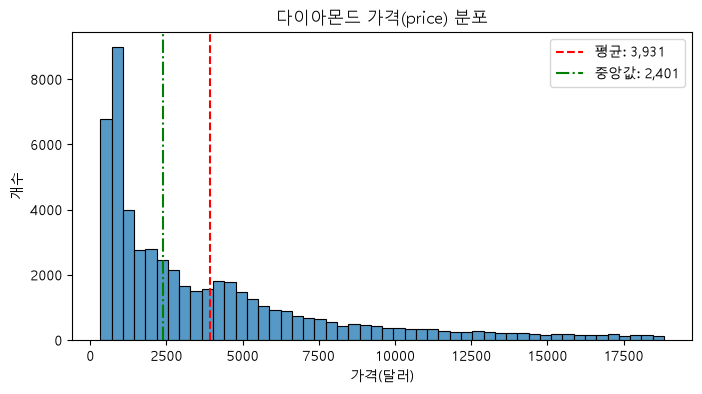

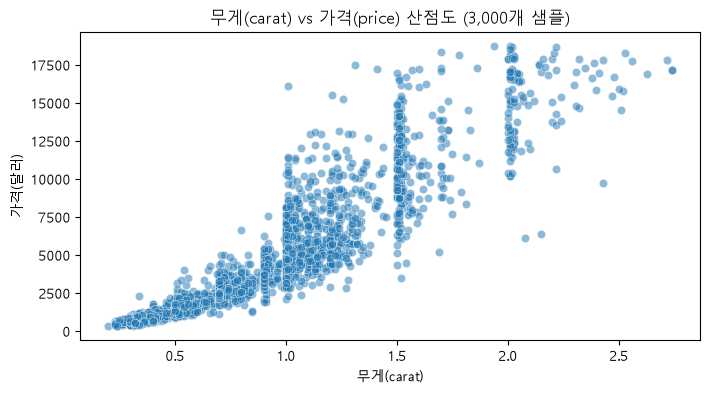

--- price와의 상관계수 순위 ---
price    1.000000
carat    0.921586
y        0.888818
x        0.887221
z        0.882107
table    0.127241
depth   -0.010653
Name: price, dtype: float64


In [16]:
# 1) price 히스토그램 + 평균/중앙값 세로선
mean_price = clean["price"].mean()
median_price = clean["price"].median()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=clean, x="price", bins=50, ax=ax)
ax.axvline(mean_price, color="red", linestyle="--", label=f"평균: {mean_price:,.0f}")
ax.axvline(median_price, color="green", linestyle="-.", label=f"중앙값: {median_price:,.0f}")
ax.set_title("다이아몬드 가격(price) 분포")
ax.set_xlabel("가격(달러)")
ax.set_ylabel("개수")
ax.legend()
plt.show()

# 2) carat과 price 산점도 (3,000개 샘플)
sample_3000 = clean.sample(3000, random_state=42)
fig, ax = plt.subplots(figsize=(8, 4))
sns.scatterplot(data=sample_3000, x="carat", y="price", alpha=0.5, ax=ax)
ax.set_title("무게(carat) vs 가격(price) 산점도 (3,000개 샘플)")
ax.set_xlabel("무게(carat)")
ax.set_ylabel("가격(달러)")
plt.show()

# 3) 숫자 열 상관계수 정렬 (price 기준 내림차순)
num_df = clean.select_dtypes("number")
corr_price = num_df.corr()["price"].sort_values(ascending=False)
print("--- price와의 상관계수 순위 ---")
print(corr_price)

### M4 · 무게로 가격 예측

#### 생각해 볼 질문
- 0.25캐럿 다이아몬드의 예상가가 음수인 이유는 무엇일까?
  직선 회귀식(`y_hat = w * x + b`)에서 기울기 `w`가 약 `7,750`, 절편 `b`가 약 `-2,252`로 계산되었기 때문입니다. `0.25 * 7750 - 2252`를 계산하면 약 `-314`가 나오며, 실제 데이터에는 없는 0캐럿 근처 직선 연장선이 음수 영역으로 내려가기 때문입니다.
- 직선이 실제 점들보다 아래 · 위로 지나가는 구간은 각각 어디인가?
  대략 `0.4캐럿`보다 작은 구간에서는 직선이 점들 아래(0 달러 아래까지)로 지나가고, `0.5~1캐럿` 부근에서는 직선이 점들 위로 지나가는 구간이 나타납니다.
- 평균 가격 가로선과 비교하면 직선은 무엇이 나아졌는가?
  평균 가격 가로선은 무게와 상관없이 항상 같은 가격만 내놓지만, 회귀직선은 무게(`carat`)가 늘수록 예측 가격도 함께 높여 주므로 실제 가격 흐름을 훨씬 잘 따라갑니다.

기울기(w): 7749.59
절편(b): -2251.69
0.250000 캐럿 예상가: -3e+02 달러
0.500000 캐럿 예상가: 2e+03 달러
1.000000 캐럿 예상가: 5e+03 달러
2.000000 캐럿 예상가: 1e+04 달러


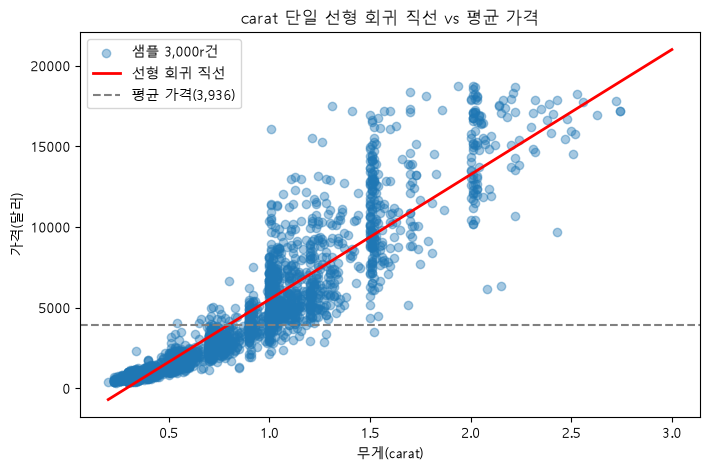

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# 1) carat 하나로 학습용 데이터 분할 (X는 2차원 표, y는 1차원 정답)
X_carat = clean[["carat"]]
y_price = clean["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X_carat, y_price, test_size=0.2, random_state=42
)

# 선형 회귀 모델 학습
model = LinearRegression()

model.fit(X_train, y_train)
model.fit(X_train, y_train)

w = model.coef_[0]
b = model.intercept_
print(f"기울기(w): {w:.2f}")
print(f"절편(b): {b:.2f}")

# 0.25, 0.5, 1.0, 2.0 캐럿 예측
new_carats = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})
pred = model.predict(new_carats)

for c, p in zip(new_carats["carat"], pred):
    print(f"{c:2f} 캐럿 예상가: {p:,.1} 달러")

# 산점도(3,000개) + 회귀직선(빨강) + 평균 가격 가로선(회색)
line_x = pd.DataFrame({"carat": [0.2, 3.0]})
line_y = model.predict(line_x)
mean_train_val = y_train.mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sample_3000["carat"], sample_3000["price"], alpha=0.4, label="샘플 3,000r건")
ax.plot(line_x["carat"], line_y, color="red", linewidth=2, label="선형 회귀 직선")
ax.axhline(mean_train_val, color="gray", linestyle="--", label=f"평균 가격({mean_train_val:,.0f})")
ax.set_title("carat 단일 선형 회귀 직선 vs 평균 가격")
ax.set_xlabel("무게(carat)")
ax.set_ylabel("가격(달러)")
ax.legend()
plt.show()

### M5 · 특성 하나씩 직선 만들기

#### 생각해 볼 질문
- 직선이 점들을 잘 따라가는 열과 못 따라가는 열은 무엇인가?
  `carat`은 점들이 직선 주변에 비교적 가깝게 모이며 흐름을 잘 따라갑니다. 반면 `x`, `y`, `z`는 곡선 형태로 휘어 직선 오차가 크고, `depth`는 거의 수평선이라 변화가 거의 없으며, `table`은 세로 띠 형태로 퍼져 직선으로 설명하기 어렵습니다.
- w(기울기)가 크면 더 좋은 열인가?
  아닙니다. `w`는 **"x가 1단위 변할 때 y가 변하는 크기"**일 뿐이어서, 열마다 측정 단위와 값의 범위(`min ~ max`)가 다르면 `w` 숫자만 보고 더 좋은 특성이라고 판단할 수 없습니다.
- M3의 상관계수 순서와 그림이 같은 이야기를 하는가?
  네, 같습니다. `price`와 상관계수가 가장 높았던 `carat`이 직선 추세를 가장 잘 나타내고, 상관관계가 거의 없던 `depth`와 `table`은 직선 설명력이 매우 낮게 나타납니다.

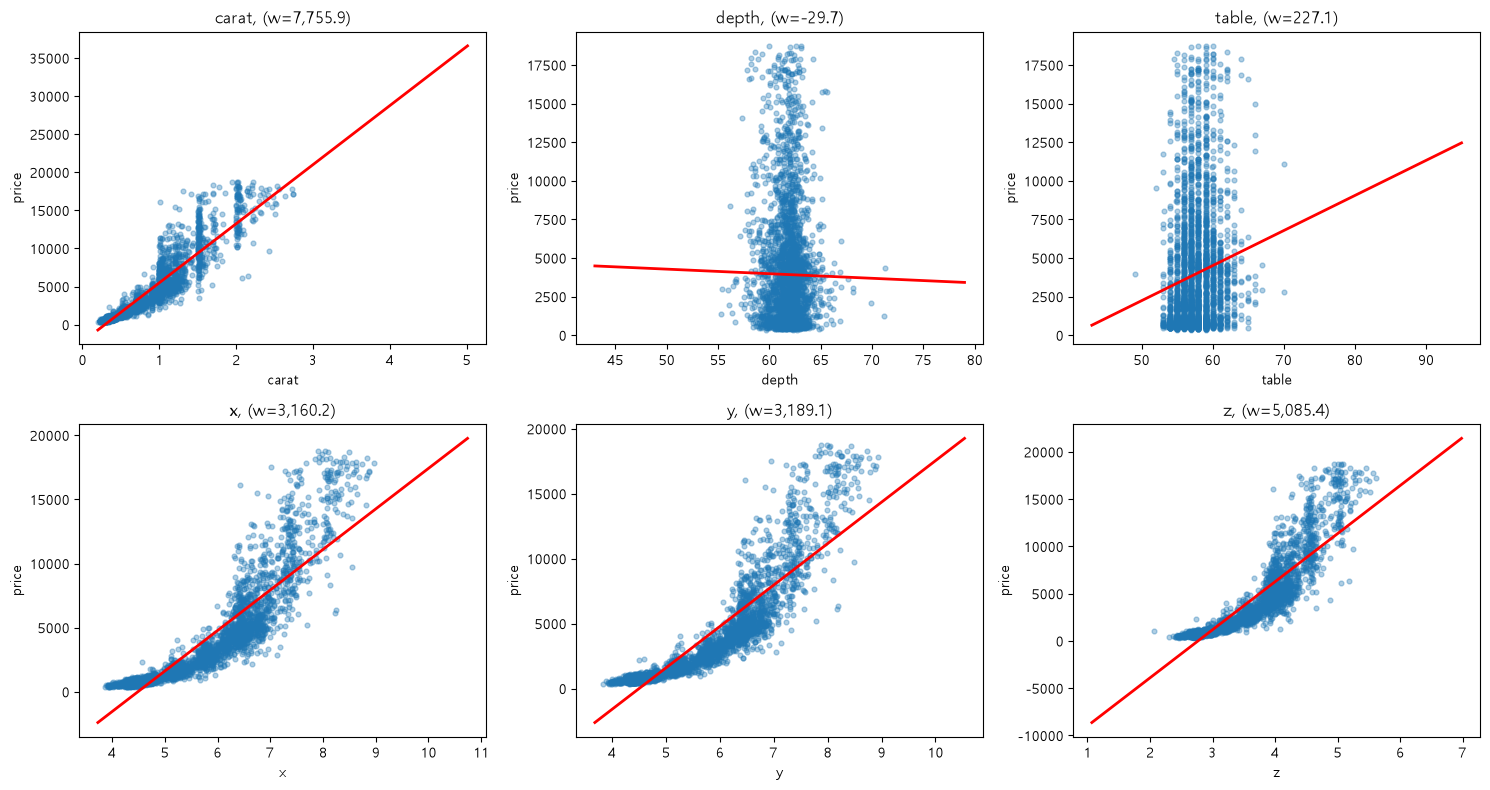

,열(feature),기울기(w),절편(b),최소값(min),최대값(max),범위(max-min)
0,carat,7755.89,-2255.86,0.20,5.01,4.81
1,depth,-29.65,5762.03,43.00,79.00,36.00
2,table,227.09,-9117.08,43.00,95.00,52.00
3,x,3160.21,-14182.15,3.73,10.74,7.01
4,y,3189.05,-14353.31,3.68,10.54,6.86
5,z,5085.38,-14068.32,1.07,6.98,5.91


In [18]:
# 숫자 6개 열 목록 (정답 열 price 제외)
num_cols = ["carat", "depth", "table", "x", "y", "z"]
y_target = clean["price"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
summary_rows = []

for ax, col in zip(axes.ravel(), num_cols):
    # 열 1개씩 선형 회귀 학습
    m = LinearRegression()
    m.fit(clean[[col]], y_target)

    col_w = m.coef_[0]
    col_b = m.intercept_
    col_min = clean[col].min()
    col_max = clean[col].max()

    # 해당 열의 최소값 ~ 최대값 양 끝점으로 직선 그리기
    x_ends = pd.DataFrame({col: [col_min, col_max]})
    y_ends = m.predict(x_ends)

    ax.scatter(sample_3000[col], sample_3000["price"], alpha=0.35, s=12)
    ax.plot(x_ends[col], y_ends, color="red", linewidth=2)
    ax.set_title(f"{col}, (w={col_w:,.1f})")
    ax.set_xlabel(col)
    ax.set_ylabel("price")

    summary_rows.append({
        "열(feature)": col,
        "기울기(w)": round(col_w, 2),
        "절편(b)": round(col_b, 2),
        "최소값(min)": round(col_min, 2),
        "최대값(max)": round(col_max, 2),
        "범위(max-min)": round(col_max - col_min, 2),
    })

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary_rows)
display(summary_df)